# Teammate 3 — AR25 dataset engineering

In [1]:
import io
import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

/Users/melissahammouche/Documents/Hof/Multimodal_AI/mm-ai-arc3-ar25


## 1. Raw files

In [2]:
raw = Path("data/raw")
for path in sorted(raw.rglob("*.json*")):
    lines = path.read_text().splitlines() if path.suffix == ".jsonl" else None
    count = len(lines) if lines is not None else len(json.loads(path.read_text()))
    print(f"{str(path):50s} records: {count}")
print("npy files:", len(list(raw.rglob("*.npy"))))

data/raw/logs/ep_001.json                          records: 7
data/raw/logs/ep_ai_001.json                       records: 30
data/raw/trajectories/sequences.jsonl              records: 1
data/raw/trajectories/transitions.jsonl            records: 11
npy files: 36


In [3]:
first = json.loads((raw / "trajectories/transitions.jsonl").read_text().splitlines()[-1])
first

{'experiment_id': '20261119T101458023164Z',
 'timestamp_utc': '2026-11-19T10:14:58.024127+00:00',
 'game_id': 'ar25-0c556536',
 'seed': 0,
 'action': 'ACTION6',
 'action_data': {'x': 36, 'y': 15},
 'before_files': ['20261119T101458023164Z_before_00.npy'],
 'after_files': ['20261119T101458023164Z_after_00.npy'],
 'before_frame_count': 1,
 'after_frame_count': 1,
 'changed_pixels_per_after_frame': [0],
 'before_state': 'GameState.NOT_FINISHED',
 'after_state': 'GameState.NOT_FINISHED',
 'levels_completed': 0,
 'win_levels': 8,
 'available_actions': [1, 2, 3, 4, 5, 6, 7],
 'full_reset': False}

In [4]:
frame = np.load(raw / "trajectories" / first["before_files"][0])
values, counts = np.unique(frame, return_counts=True)
print("shape:", frame.shape, "dtype:", frame.dtype)
pd.DataFrame({"colour": values, "pixels": counts})

shape: (64, 64) dtype: int8


,colour,pixels
0,0,5
1,4,45
2,5,103
3,9,3645
4,10,189
5,11,109


## 2. Build the Parquet dataset

In [5]:
result = subprocess.run(
    [sys.executable, "scripts/14_build_parquet_dataset.py", "--output", "data/processed/ar25_transitions_full.parquet"],
    capture_output=True, text=True,
)
print("\n".join(result.stdout.splitlines()[:3]))
print("\n".join(result.stdout.splitlines()[-9:-6]))

Loaded 53 raw transitions
Kept 52 complete transitions, skipped 1 incomplete
  20261119T114919387876Z_step001           ACTION1  changed= 109

Saved 52 rows to data/processed/ar25_transitions_full.parquet
Duplicates flagged: 11


In [6]:
df = pd.read_parquet("data/processed/ar25_transitions_full.parquet")
lisa = pd.read_parquet("data/processed/ar25_transitions.parquet")
print("full dataset:", df.shape, "| LISA test set:", lisa.shape)
pd.DataFrame({"dtype": df.dtypes.astype(str), "example": df.iloc[0].map(lambda v: str(v)[:60])})

full dataset: (52, 23) | LISA test set: (5, 23)


,dtype,example
sample_id,object,20261119T114919387876Z_step001
source,object,sequences.jsonl
episode_id,object,20261119T114919387876Z
step,int64,1
action,object,ACTION1
action_id,int64,1
action_data,object,{}
before_state,object,NOT_FINISHED
after_state,object,NOT_FINISHED
levels_completed,float64,0.0


## 3. Content overview

In [7]:
pd.concat(
    [df["action"].value_counts().rename("rows"),
     df.groupby("action")["changed_pixels"].mean().round(1).rename("mean changed pixels")],
    axis=1,
)

,rows,mean changed pixels
action,,
ACTION1,27,72.7
ACTION2,11,109.0
ACTION6,4,0.0
ACTION3,3,109.0
ACTION4,3,109.0
ACTION5,3,1.0
ACTION7,1,0.0


In [8]:
pd.DataFrame({
    "rows": df.groupby("source").size(),
    "duplicates": df.groupby("source")["is_duplicate"].sum(),
    "no visible change": df.groupby("source")["changed_pixels"].apply(lambda s: int((s == 0).sum())),
})

,rows,duplicates,no visible change
source,,,
logs/ep_001.json,6,5,1
logs/ep_ai_001.json,30,1,9
sequences.jsonl,5,0,0
transitions.jsonl,11,5,4


## 4. One transition

20261119T114919387876Z_step001 | ACTION1 | changed pixels: 109


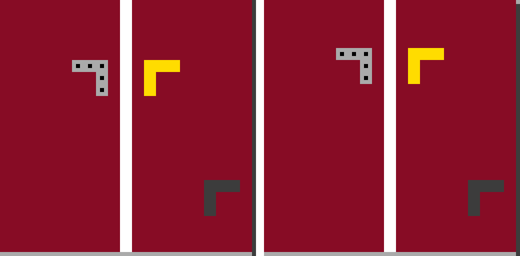

109 pixels changed inside the region x=18..63, y=0..23. Colour 0 shape shifted by dx=0, dy=-3. Colour 4 shape shifted by dx=0, dy=-3. Colour 5 pixel count 103 -> 104. Colour 11 pixel count 109 -> 108.


In [9]:
def show_pair(row):
    before = Image.open(io.BytesIO(row["image_before"]["bytes"]))
    after = Image.open(io.BytesIO(row["image_after"]["bytes"]))
    canvas = Image.new("RGB", (before.width * 2 + 16, before.height), "white")
    canvas.paste(before, (0, 0))
    canvas.paste(after, (before.width + 16, 0))
    display(canvas.resize((canvas.width // 2, canvas.height // 2)))

row = df.iloc[0]
print(row["sample_id"], "|", row["action"], "| changed pixels:", row["changed_pixels"])
show_pair(row)
print(row["observation"])

## 5. Reasoning traces: observed diff vs LISA

In [10]:
sample = lisa.iloc[0]["sample_id"]
print("observed_diff:\n", df.set_index("sample_id").loc[sample, "reasoning"], "\n")
print(lisa.iloc[0]["reasoning_source"] + ":\n", lisa.iloc[0]["reasoning"])

observed_diff:
 Observation: I executed ACTION1. 109 pixels changed inside the region x=18..63, y=0..23. Colour 0 shape shifted by dx=0, dy=-3. Colour 4 shape shifted by dx=0, dy=-3. Colour 5 pixel count 103 -> 104. Colour 11 pixel count 109 -> 108. Game state afterwards: NOT_FINISHED. 

lisa:lisa-pro:
 Reasoning before action: I see a grid with several colored shapes, including a large background or structural element in colour 5 and some objects in colours 0, 4, and 11. I haven't yet established what ACTION1 does in this game. Hypothesis: ACTION1 might move the player-controlled objects upward, since many grid games map the first action to a directional input. I'll try it and observe which shapes respond.

Observation after ACTION1: The colour 0 shape and the colour 4 shape both shifted up by 3 pixels (dx=0, dy=-3), suggesting they move together, possibly as a linked group or player entity. The colour 5 pixel count increased slightly (103 to 104), and the colour 11 pixel count decrea

## 6. Fine-tuning format (Lab 4)

In [11]:
def convert_to_conversation(sample):
    return {"messages": [
        {"role": "user", "content": [
            {"type": "text", "text": sample["instruction"]},
            {"type": "image", "image": sample["image_before"]["path"]},
        ]},
        {"role": "assistant", "content": [{"type": "text", "text": sample["answer"]}]},
    ]}

json.loads(json.dumps(convert_to_conversation(lisa.iloc[0])))

{'messages': [{'role': 'user',
   'content': [{'type': 'text',
     'text': 'You are playing the ARC-AGI-3 game AR25 on a 64x64 grid. Look at the current frame and decide which action to take next. Explain your reasoning, then give the action.'},
    {'type': 'image', 'image': '20261119T114919387876Z_step001_before.png'}]},
  {'role': 'assistant',
   'content': [{'type': 'text',
     'text': "Reasoning before action: I see a grid with several colored shapes, including a large background or structural element in colour 5 and some objects in colours 0, 4, and 11. I haven't yet established what ACTION1 does in this game. Hypothesis: ACTION1 might move the player-controlled objects upward, since many grid games map the first action to a directional input. I'll try it and observe which shapes respond.\n\nObservation after ACTION1: The colour 0 shape and the colour 4 shape both shifted up by 3 pixels (dx=0, dy=-3), suggesting they move together, possibly as a linked group or player entity. T

## 7. Validation

In [12]:
result = subprocess.run([sys.executable, "scripts/validate_dataset.py"], capture_output=True, text=True)
print(result.stdout.splitlines()[0])
display(Markdown(Path("reports/validation_report.md").read_text()))

Status: PASS (0 errors, 3 warnings)


# AR25 dataset validation report

Generated: 2026-11-20 01:50 UTC  
Command: `python scripts/validate_dataset.py`  
Status: **PASS** (0 errors, 3 warnings)

## Raw data (`data/raw/`)

| Item | Count |
|---|---|
| sequential trajectories | 1 |
| sequential steps | 5 |
| single action transitions | 11 |
| episode log steps | 37 |
| npy frame files | 33 |
| orphan npy files | 0 |

## Processed dataset `data/processed/ar25_transitions.parquet`

| Item | Value |
|---|---|
| rows | 5 |
| unique transitions | 5 |
| duplicate transitions | 0 |
| rows with no visible change | 0 |
| actions | ACTION1: 1, ACTION2: 1, ACTION3: 1, ACTION4: 1, ACTION5: 1 |
| sources | sequences.jsonl: 5 |
| reasoning | lisa:lisa-pro: 5 |

## Processed dataset `data/processed/ar25_transitions_full.parquet`

| Item | Value |
|---|---|
| rows | 52 |
| unique transitions | 41 |
| duplicate transitions | 11 |
| rows with no visible change | 14 |
| actions | ACTION1: 27, ACTION2: 11, ACTION3: 3, ACTION4: 3, ACTION5: 3, ACTION6: 4, ACTION7: 1 |
| sources | logs/ep_001.json: 6, logs/ep_ai_001.json: 30, sequences.jsonl: 5, transitions.jsonl: 11 |
| reasoning | observed_diff: 52 |

## Checks

| Check | Errors | Warnings |
|---|---|---|
| missing_file | 0 | 0 |
| unreadable_file | 0 | 0 |
| malformed_json | 0 | 0 |
| missing_field | 0 | 0 |
| dimensions | 0 | 0 |
| value_range | 0 | 0 |
| step_order | 0 | 0 |
| broken_sequence | 0 | 0 |
| incomplete_transition | 0 | 1 |
| duplicate_record | 0 | 0 |
| duplicate_transition | 0 | 1 |
| duplicate_flag | 0 | 0 |
| changed_pixels_mismatch | 0 | 0 |
| hash_mismatch | 0 | 0 |
| schema | 0 | 0 |
| orphan_file | 0 | 0 |
| legacy_format | 0 | 1 |

## Findings

| Level | Check | Target | Message |
|---|---|---|---|
| WARNING | legacy_format | `data/raw/trajectories/transitions.jsonl:20261119T100908020911Z` | uses before_file/after_file instead of *_files lists |
| WARNING | incomplete_transition | `data/raw/logs/ep_001.json:step6` | last step has no next_grid_state, so its after frame is unknown |
| WARNING | duplicate_transition | `data/processed/ar25_transitions_full.parquet` | 11 rows repeat an identical (before, action, after) transition |
